# A/B-тест нового экрана оплаты

**Контекст.** Интернет-магазин переделал экран оплаты: вместо трёх шагов — одна страница, сохранённые карты и оплата через Apple Pay / Google Pay. Продуктовая команда хочет понять, стоит ли выкатывать новый экран на всех пользователей.

**Гипотеза.** Новый экран снижает трение при оплате, поэтому доля пользователей, дошедших до экрана оплаты и совершивших покупку, вырастет.

| | Метрика | Определение |
|---|---|---|
| Основная | Конверсия в покупку | доля пользователей экрана оплаты, оформивших заказ |
| Вторичная | ARPU | выручка на одного пользователя экрана оплаты |
| Контрольная (guardrail) | Средний чек (AOV) | выручка на один заказ — снижение не более чем на 3% |

**Дизайн.** Сплит 50/50 по `user_id`, длительность 14 дней (2 полные недели, чтобы покрыть недельную сезонность), α = 0.05, мощность 80%.

> Данные синтетические: сгенерированы скриптом `src/generate_data.py` с реалистичными артефактами (дубли, пересечения групп, тестовый трафик).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
from statsmodels.stats.multitest import multipletests

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import ab_stats as ab

IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)

ALPHA = 0.05
COL = {"A": "#2a78d6", "B": "#eb6834"}   # A — контроль, B — тест
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Дизайн эксперимента: сколько нужно пользователей

До запуска по историческим данным конверсия экрана оплаты ≈ **26%**. Минимальный эффект, который интересен бизнесу (MDE), — **+1.5 п.п.** (≈ +6% относительно): меньший прирост не окупает поддержку нового экрана.

In [2]:
P_BASE, MDE = 0.26, 0.015
n_needed = ab.sample_size_proportion(P_BASE, MDE, alpha=ALPHA, power=0.8)
daily_traffic = 3_700   # пользователей экрана оплаты в день (исторически)
print(f"Нужно пользователей на группу: {n_needed:,}")
print(f"Всего: {2*n_needed:,} → ≈ {2*n_needed/daily_traffic:.1f} дня трафика")

Нужно пользователей на группу: 13,669
Всего: 27,338 → ≈ 7.4 дня трафика


По расчёту хватило бы ~7–8 дней, но тест запущен на **14 дней**: так в него попадают две полные недели (поведение в выходные отличается), а запас по выборке позволяет смотреть на сегменты.

## 2. Загрузка и очистка данных

In [3]:
raw = pd.read_csv(ROOT / "data" / "checkout_ab_test.csv", parse_dates=["event_time"])
print(raw.shape)
raw.head()

(52982, 7)


,user_id,group,event_time,platform,user_type,converted,revenue
0,102669,A,2026-09-13 23:13:23,ios,new,0,0.0000
1,117417,B,2026-09-13 18:13:27,ios,returning,1,"1,640.0000"
2,144611,B,2026-09-12 17:28:47,android,new,0,0.0000
3,142515,A,2026-09-06 18:08:45,android,returning,1,"2,400.0000"
4,112934,A,2026-09-14 08:44:43,ios,new,0,0.0000


In [4]:
raw.info()
raw.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 52982 entries, 0 to 52981
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     52982 non-null  int64         
 1   group       52982 non-null  str           
 2   event_time  52982 non-null  datetime64[us]
 3   platform    52982 non-null  str           
 4   user_type   52982 non-null  str           
 5   converted   52982 non-null  int64         
 6   revenue     52982 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(2), str(3)
memory usage: 2.8 MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
user_id,"52,982.0000",NaN,NaN,NaN,"128,179.8991","100,001.0000","113,009.2500","126,056.5000","139,097.7500","900,150.0000","43,777.2154"
group,52982,2,B,26579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_time,52982,NaN,NaN,NaN,2026-09-08 02:21:35.667396,2026-09-01 00:00:02,2026-09-04 17:23:48.500000,2026-09-07 23:19:49,2026-09-11 18:31:37,2026-09-15 22:08:37,NaN
platform,52982,3,ios,19936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_type,52982,2,returning,29282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
converted,"52,982.0000",NaN,NaN,NaN,0.2717,0.0000,0.0000,0.0000,1.0000,1.0000,0.4448
revenue,"52,982.0000",NaN,NaN,NaN,"1,153.6663",0.0000,0.0000,0.0000,"1,050.0000","50,610.0000","2,731.8348"


Проверяем типичные проблемы логов: полные дубли, тестовые аккаунты, пользователей в обеих группах.

In [5]:
log = {"Исходно строк": len(raw)}

df = raw.drop_duplicates()
log["После удаления полных дублей"] = len(df)

# QA-аккаунты: id из служебного диапазона 900000+, все в группе B и с выручкой 1 руб.
qa = df[df["user_id"] >= 900_000]
print("QA-трафик:", qa.shape[0], "строк; группы:", qa["group"].unique(), "; выручка:", qa["revenue"].unique())
df = df[df["user_id"] < 900_000]
log["После удаления QA-трафика"] = len(df)

# Пользователи, попавшие в обе группы (баг сплитования) — исключаем целиком
groups_per_user = df.groupby("user_id")["group"].nunique()
both = groups_per_user[groups_per_user > 1].index
print(f"Пользователей в обеих группах: {len(both)} ({len(both)/df.user_id.nunique():.2%})")
df = df[~df["user_id"].isin(both)]
log["После удаления пересечений"] = len(df)

assert df["user_id"].is_unique
pd.Series(log, name="строк").to_frame()

QA-трафик: 150 строк; группы: <StringArray>
['B']
Length: 1, dtype: str ; выручка: [1.]


Пользователей в обеих группах: 312 (0.60%)


,строк
Исходно строк,52982
После удаления полных дублей,52462
После удаления QA-трафика,52312
После удаления пересечений,51688


**Что нашли:**
- ~1% полных дублей строк — повторная отправка событий;
- 150 QA-аккаунтов только в группе B, каждый «купил» на 1 руб. — они завышали бы конверсию теста;
- ~0.6% пользователей видели оба экрана — их поведение нельзя отнести ни к одной группе, исключаем целиком (доля мала и одинакова в группах, смещения не вносит).

## 3. Проверка корректности сплита (SRM)

Sample Ratio Mismatch — расхождение фактического соотношения групп с заложенным (50/50). Если SRM есть, рандомизация сломана, и результатам теста верить нельзя. Проверяем хи-квадрат тестом; порог строже обычного — p < 0.001.

In [6]:
def srm_report(d, label):
    n = d["group"].value_counts()
    p = ab.srm_check(n["A"], n["B"])
    return {"данные": label, "A": n["A"], "B": n["B"], "доля A": n["A"]/n.sum(), "p-value": p,
            "SRM?": "ДА" if p < 0.001 else "нет"}

srm = pd.DataFrame([srm_report(raw.drop_duplicates(), "до очистки"), srm_report(df, "после очистки")])
srm

,данные,A,B,доля A,p-value,SRM?
0,до очистки,26134,26328,0.4982,0.3970,нет
1,после очистки,25822,25866,0.4996,0.8465,нет


In [7]:
# SRM внутри сегментов: перекос может прятаться в отдельной платформе
seg_srm = (df.groupby(["platform", "group"]).size().unstack()
             .assign(p_value=lambda t: [ab.srm_check(a, b) for a, b in zip(t.A, t.B)]))
seg_srm

group,A,B,p_value
platform,,,
android,8797,8935,0.3000
ios,9652,9790,0.3223
web,7373,7141,0.0541


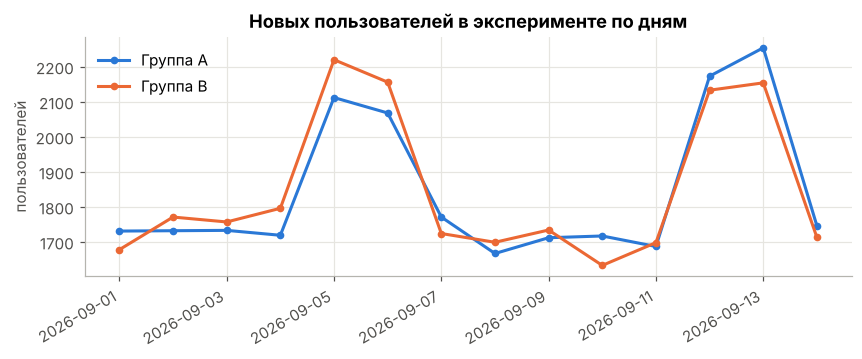

In [8]:
daily_n = df.groupby([df.event_time.dt.date, "group"]).size().unstack()
fig, ax = plt.subplots(figsize=(9, 3.2))
for g in ["A", "B"]:
    ax.plot(daily_n.index, daily_n[g], marker="o", ms=4, lw=2, color=COL[g], label=f"Группа {g}")
ax.set_title("Новых пользователей в эксперименте по дням")
ax.set_ylabel("пользователей")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.savefig(IMG / "01_daily_users.png")
plt.show()

SRM нет ни в целом, ни внутри платформ; трафик в группах идёт синхронно по дням (с ожидаемыми пиками в выходные). Сплит корректен, переходим к метрикам.

## 4. Хватает ли выборки: фактический MDE

In [9]:
n_a, n_b = df.group.value_counts()[["A", "B"]]
p_a_obs = df.loc[df.group == "A", "converted"].mean()
mde_obs = ab.mde_proportion(p_a_obs, min(n_a, n_b))
print(f"Пользователей: A={n_a:,}, B={n_b:,} (план: {n_needed:,} на группу)")
print(f"Фактический MDE при 80% мощности: {mde_obs*100:.2f} п.п. (план: {MDE*100:.1f} п.п.)")

Пользователей: A=25,822, B=25,866 (план: 13,669 на группу)
Фактический MDE при 80% мощности: 1.08 п.п. (план: 1.5 п.п.)


## 5. Проверка метода: A/A-симуляция

Прежде чем доверять p-value, убеждаемся, что z-тест на этих данных даёт ровно ~5% ложных срабатываний. Для этого 1 000 раз случайно делим контрольную группу пополам и считаем, как часто тест «находит» несуществующий эффект.

In [10]:
conv_a_arr = df.loc[df.group == "A", "converted"].to_numpy()
fpr = ab.aa_false_positive_rate(conv_a_arr, ab.ztest_proportions, n_sim=1_000, seed=1)
lo, hi = stats.binomtest(int(fpr*1000), 1000).proportion_ci()
print(f"Доля ложных срабатываний: {fpr:.1%} (95% ДИ {lo:.1%}–{hi:.1%}); ожидаем ≈ 5%")

Доля ложных срабатываний: 5.0% (95% ДИ 3.7%–6.5%); ожидаем ≈ 5%


## 6. Основная метрика: конверсия в покупку

In [11]:
A = df[df.group == "A"]
B = df[df.group == "B"]

res_cr = ab.ztest_proportions(A.converted.to_numpy(), B.converted.to_numpy(), metric="Конверсия")
pd.Series(res_cr.as_dict())

metric       Конверсия
control         0.2583
treatment       0.2809
abs_diff        0.0226
rel_diff        0.0877
ci_low          0.0150
ci_high         0.0303
p_value         0.0000
dtype: object

In [12]:
print(f"Конверсия: A = {res_cr.control:.2%}, B = {res_cr.treatment:.2%}")
print(f"Разница: {res_cr.abs_diff*100:+.2f} п.п. (95% ДИ {res_cr.ci_low*100:+.2f} … {res_cr.ci_high*100:+.2f} п.п.)")
print(f"Относительный прирост: {res_cr.rel_diff:+.1%}")
print(f"p-value: {res_cr.p_value:.2e}")

Конверсия: A = 25.83%, B = 28.09%
Разница: +2.26 п.п. (95% ДИ +1.50 … +3.03 п.п.)
Относительный прирост: +8.8%
p-value: 6.64e-09


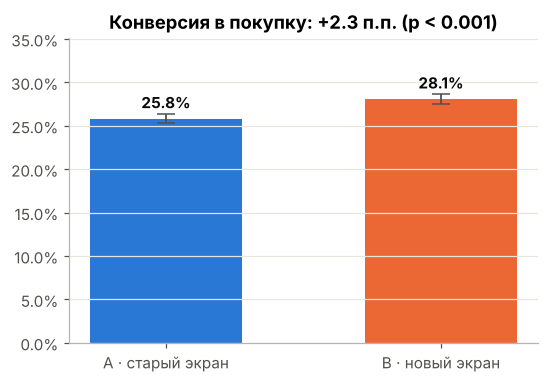

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
vals = [res_cr.control, res_cr.treatment]
se = [np.sqrt(p*(1-p)/n) * 1.96 for p, n in zip(vals, [len(A), len(B)])]
bars = ax.bar(["A · старый экран", "B · новый экран"], vals, yerr=se, capsize=6,
              color=[COL["A"], COL["B"]], width=0.55, error_kw={"ecolor": "#52514e", "lw": 1.2})
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.012, f"{v:.1%}", ha="center", fontweight="bold", color="#0b0b0b")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, max(vals) * 1.25)
ax.set_title(f"Конверсия в покупку: {res_cr.abs_diff*100:+.1f} п.п. (p < 0.001)")
ax.grid(axis="x", visible=False)
fig.savefig(IMG / "02_conversion.png")
plt.show()

### Динамика: устойчив ли эффект и нет ли эффекта новизны

Подглядывать в тест и останавливать его при первом «значимом» p-value нельзя (peeking завышает долю ложноположительных). Но посмотреть на динамику после окончания полезно: эффект должен быть стабильным, а не держаться только на первых днях.

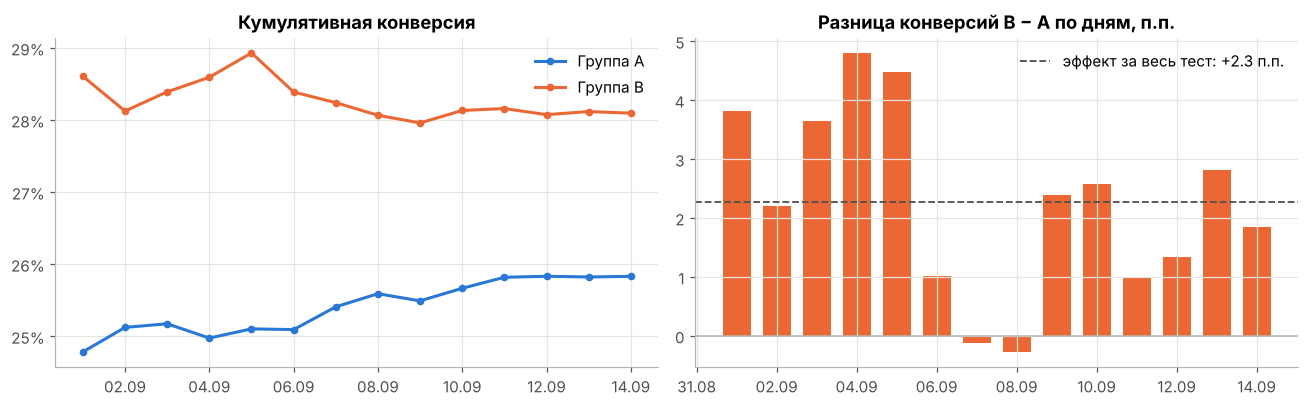

In [14]:
d = df.assign(day=df.event_time.dt.normalize())
daily = d.groupby(["day", "group"])["converted"].agg(["sum", "count"]).unstack()
cum = daily.cumsum()
cum_cr = cum["sum"] / cum["count"]
daily_cr = daily["sum"] / daily["count"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
for g in ["A", "B"]:
    ax.plot(cum_cr.index, cum_cr[g], lw=2, marker="o", ms=4, color=COL[g], label=f"Группа {g}")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("Кумулятивная конверсия")
ax.legend(frameon=False)

ax = axes[1]
diff = (daily_cr["B"] - daily_cr["A"]) * 100
ax.bar(diff.index, diff, color=COL["B"], width=0.7)
ax.axhline(res_cr.abs_diff * 100, color="#52514e", ls="--", lw=1.2, label=f"эффект за весь тест: {res_cr.abs_diff*100:+.1f} п.п.")
ax.axhline(0, color="#b5b4ae", lw=1)
ax.set_title("Разница конверсий B − A по дням, п.п.")
ax.legend(frameon=False, loc="upper right")
import matplotlib.dates as mdates
for a in axes:
    a.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
    a.xaxis.set_major_locator(mdates.DayLocator(interval=2))
fig.tight_layout()
fig.savefig(IMG / "03_dynamics.png")
plt.show()

In [15]:
# Эффект без первых трёх дней — проверка на эффект новизны
late = d[d.day >= d.day.min() + pd.Timedelta(days=3)]
res_late = ab.ztest_proportions(late.loc[late.group == "A", "converted"].to_numpy(),
                                late.loc[late.group == "B", "converted"].to_numpy())
print(f"Дни 1–3:  {(daily_cr['B'] - daily_cr['A']).iloc[:3].mean()*100:+.2f} п.п. (в среднем по дням)")
print(f"Дни 4–14: {res_late.abs_diff*100:+.2f} п.п. (ДИ {res_late.ci_low*100:+.2f} … {res_late.ci_high*100:+.2f}), p = {res_late.p_value:.1e}")

Дни 1–3:  +3.22 п.п. (в среднем по дням)
Дни 4–14: +2.02 п.п. (ДИ +1.17 … +2.88), p = 3.6e-06


В первые дни прирост чуть выше (типичный эффект новизны: пользователи «пробуют» новое), но и после его затухания эффект остаётся значимым и близким к общему. Кумулятивные кривые не пересекаются ни разу, а к концу теста стабилизировались: разрыв не сокращается. Отдельные дни с нулевой разницей — обычный шум дневных выборок (~3.7 тыс. пользователей в день).

## 7. ARPU и средний чек

Выручка распределена с тяжёлым правым хвостом и множеством нулей (не купившие), поэтому помимо t-теста Уэлча (по ЦПТ он корректен на больших выборках) делаем **бутстрап** — он не требует предположений о форме распределения и даёт честный доверительный интервал.

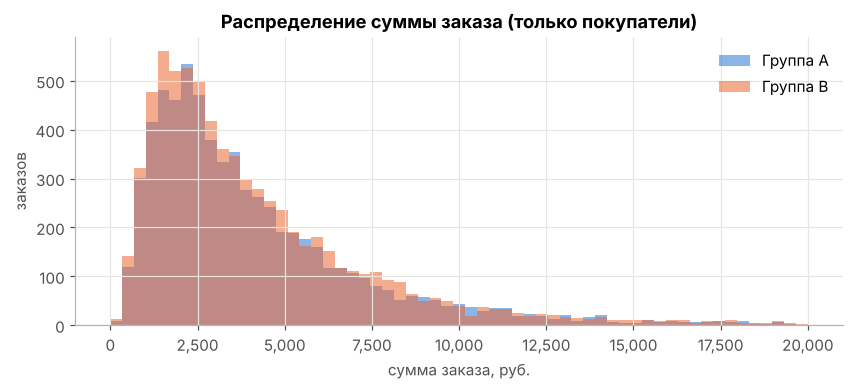

Скошенность суммы заказа: 3.12


In [16]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.linspace(0, 20_000, 60)
for g, sub in [("A", A), ("B", B)]:
    ax.hist(sub.loc[sub.converted == 1, "revenue"], bins=bins, alpha=0.55, color=COL[g], label=f"Группа {g}")
ax.set_title("Распределение суммы заказа (только покупатели)")
ax.set_xlabel("сумма заказа, руб.")
ax.set_ylabel("заказов")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False)
fig.savefig(IMG / "04_revenue_distribution.png")
plt.show()
print("Скошенность суммы заказа:", round(stats.skew(df.loc[df.converted == 1, "revenue"]), 2))

In [17]:
rev_a, rev_b = A.revenue.to_numpy(), B.revenue.to_numpy()
aov_a = A.loc[A.converted == 1, "revenue"].to_numpy()
aov_b = B.loc[B.converted == 1, "revenue"].to_numpy()

res_arpu = ab.welch_ttest(rev_a, rev_b, metric="ARPU")
boot_arpu = ab.bootstrap_diff(rev_a, rev_b, np.mean, n_boot=5_000, seed=7)

res_aov = ab.welch_ttest(aov_a, aov_b, metric="Средний чек")
boot_aov = ab.bootstrap_diff(aov_a, aov_b, np.mean, n_boot=5_000, seed=8)
boot_med = ab.bootstrap_diff(aov_a, aov_b, np.median, n_boot=5_000, seed=9)
mw = stats.mannwhitneyu(aov_b, aov_a, alternative="two-sided")

summary = pd.DataFrame([
    {"метрика": "ARPU, руб.", "A": rev_a.mean(), "B": rev_b.mean(), "разница": boot_arpu["observed"],
     "ДИ (бутстрап)": f"{boot_arpu['ci_low']:+.0f} … {boot_arpu['ci_high']:+.0f}",
     "p (t-тест)": res_arpu.p_value, "p (бутстрап)": boot_arpu["p_value"]},
    {"метрика": "Средний чек, руб.", "A": aov_a.mean(), "B": aov_b.mean(), "разница": boot_aov["observed"],
     "ДИ (бутстрап)": f"{boot_aov['ci_low']:+.0f} … {boot_aov['ci_high']:+.0f}",
     "p (t-тест)": res_aov.p_value, "p (бутстрап)": boot_aov["p_value"]},
    {"метрика": "Медианный чек, руб.", "A": np.median(aov_a), "B": np.median(aov_b), "разница": boot_med["observed"],
     "ДИ (бутстрап)": f"{boot_med['ci_low']:+.0f} … {boot_med['ci_high']:+.0f}",
     "p (t-тест)": np.nan, "p (бутстрап)": boot_med["p_value"]},
])
print(f"Манна-Уитни для суммы заказа: p = {mw.pvalue:.3f}")
summary.style.format({"A": "{:,.0f}", "B": "{:,.0f}", "разница": "{:+,.0f}", "p (t-тест)": "{:.4f}", "p (бутстрап)": "{:.4f}"}, na_rep="—")

Манна-Уитни для суммы заказа: p = 0.928


,метрика,A,B,разница,ДИ (бутстрап),p (t-тест),p (бутстрап)
0,"ARPU, руб.","1,100","1,210",+110,+60 … +158,0.0000,0.0002
1,"Средний чек, руб.","4,259","4,307",+48,-73 … +174,0.4485,0.4332
2,"Медианный чек, руб.","3,215","3,200",-15,-120 … +110,—,0.9184


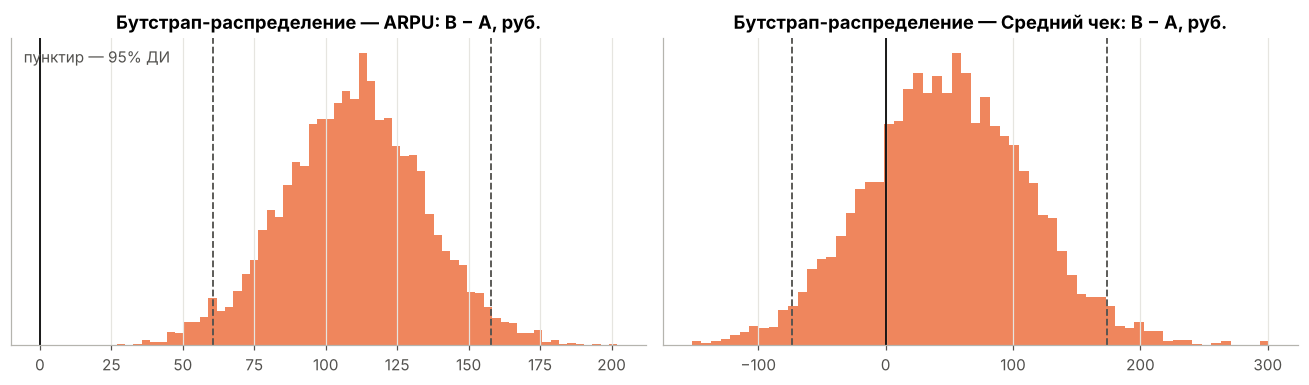

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, boot, title in [(axes[0], boot_arpu, "ARPU: B − A, руб."), (axes[1], boot_aov, "Средний чек: B − A, руб.")]:
    ax.hist(boot["diffs"], bins=60, color=COL["B"], alpha=0.8)
    ax.axvline(0, color="#0b0b0b", lw=1.2)
    for q in (boot["ci_low"], boot["ci_high"]):
        ax.axvline(q, color="#52514e", ls="--", lw=1.2)
    ax.set_title(f"Бутстрап-распределение — {title}")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes[0].text(0.02, 0.92, "пунктир — 95% ДИ", transform=axes[0].transAxes, color="#52514e")
fig.tight_layout()
fig.savefig(IMG / "05_bootstrap.png")
plt.show()

- **ARPU вырос** значимо: ДИ разницы целиком выше нуля. Рост идёт за счёт конверсии.
- **Средний чек (guardrail) не упал**: разница статистически незначима, ДИ включает ноль, а его нижняя граница (≈ −1.7%) не выходит за допустимое снижение в −3%. Новый экран не «размывает» корзину.

## 8. Сегменты: где эффект сильнее

Сегментный анализ — разведочный: проверяем много гипотез сразу, поэтому корректируем p-value на множественное сравнение (поправка Холма). Решение принимается по основной метрике, сегменты помогают понять, *почему* работает эффект.

In [19]:
rows = []
for col in ["platform", "user_type"]:
    for val, sub in df.groupby(col):
        r = ab.ztest_proportions(sub.loc[sub.group == "A", "converted"].to_numpy(),
                                 sub.loc[sub.group == "B", "converted"].to_numpy())
        rows.append({"срез": col, "сегмент": val, "n": len(sub), "CR A": r.control, "CR B": r.treatment,
                     "Δ, п.п.": r.abs_diff*100, "ДИ low": r.ci_low*100, "ДИ high": r.ci_high*100, "p": r.p_value})
seg = pd.DataFrame(rows)
seg["p (Холм)"] = multipletests(seg["p"], method="holm")[1]
seg["значимо"] = np.where(seg["p (Холм)"] < ALPHA, "да", "нет")
seg.style.format({"n": "{:,}", "CR A": "{:.1%}", "CR B": "{:.1%}", "Δ, п.п.": "{:+.2f}",
                  "ДИ low": "{:+.2f}", "ДИ high": "{:+.2f}", "p": "{:.4f}", "p (Холм)": "{:.4f}"})

,срез,сегмент,n,CR A,CR B,"Δ, п.п.",ДИ low,ДИ high,p,p (Холм),значимо
0,platform,android,"17,732",23.6%,26.8%,+3.14,+1.86,+4.42,0.0000,0.0000,да
1,platform,ios,"19,442",27.5%,30.0%,+2.47,+1.20,+3.74,0.0001,0.0003,да
2,platform,web,"14,514",26.3%,27.2%,+0.91,-0.53,+2.35,0.2156,0.2156,нет
3,user_type,new,"23,240",20.1%,22.3%,+2.24,+1.19,+3.29,0.0000,0.0001,да
4,user_type,returning,"28,448",30.5%,32.9%,+2.37,+1.29,+3.45,0.0000,0.0001,да


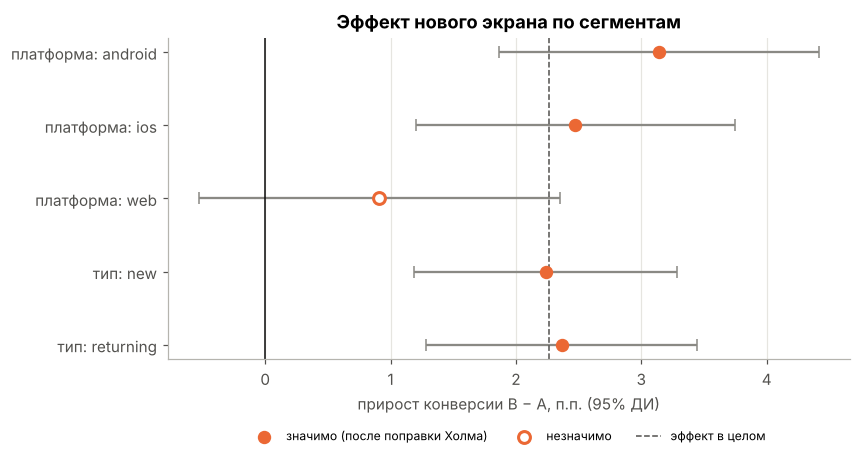

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.8))
lab = seg["срез"].map({"platform": "платформа", "user_type": "тип"}) + ": " + seg["сегмент"]
y = np.arange(len(seg))[::-1]
sig = seg["значимо"] == "да"
ax.errorbar(seg["Δ, п.п."], y, xerr=[seg["Δ, п.п."] - seg["ДИ low"], seg["ДИ high"] - seg["Δ, п.п."]],
            fmt="none", ecolor="#8a8984", capsize=4, lw=1.5)
ax.scatter(seg.loc[sig, "Δ, п.п."], y[sig], s=60, color=COL["B"], zorder=3, label="значимо (после поправки Холма)")
ax.scatter(seg.loc[~sig, "Δ, п.п."], y[~sig], s=60, facecolor="white", edgecolor=COL["B"], lw=2, zorder=3, label="незначимо")
ax.axvline(0, color="#0b0b0b", lw=1)
ax.axvline(res_cr.abs_diff*100, color="#52514e", ls="--", lw=1, label="эффект в целом")
ax.set_yticks(y, lab)
ax.set_xlabel("прирост конверсии B − A, п.п. (95% ДИ)")
ax.set_title("Эффект нового экрана по сегментам")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8)
ax.grid(axis="y", visible=False)
fig.savefig(IMG / "06_segments.png")
plt.show()

Эффект сосредоточен на **мобильных платформах** (iOS и Android): там новый экран добавил Apple Pay / Google Pay, и оплата стала заметно короче. На вебе прирост небольшой и статистически незначим — гипотеза для следующей итерации: добавить на вебе быстрые способы оплаты (например, SBP / сохранённые карты по умолчанию). Для новых и вернувшихся пользователей эффект сопоставим.

## 9. Влияние на бизнес

In [21]:
MONTHLY_CHECKOUT_USERS = daily_traffic * 30
extra_orders = MONTHLY_CHECKOUT_USERS * np.array([res_cr.ci_low, res_cr.abs_diff, res_cr.ci_high])
extra_rev = MONTHLY_CHECKOUT_USERS * np.array([boot_arpu["ci_low"], boot_arpu["observed"], boot_arpu["ci_high"]])
pd.DataFrame({"пессимистично (ДИ low)": [extra_orders[0], extra_rev[0]],
              "оценка": [extra_orders[1], extra_rev[1]],
              "оптимистично (ДИ high)": [extra_orders[2], extra_rev[2]]},
             index=["доп. заказов в месяц", "доп. выручка в месяц, руб."]).style.format("{:,.0f}")

,пессимистично (ДИ low),оценка,оптимистично (ДИ high)
доп. заказов в месяц,"1,664","2,513","3,362"
"доп. выручка в месяц, руб.","6,706,296","12,207,665","17,514,217"


## 10. Итог и рекомендация

In [22]:
print(f'''
Основная метрика  — конверсия: {res_cr.control:.2%} → {res_cr.treatment:.2%}  ({res_cr.abs_diff*100:+.2f} п.п., {res_cr.rel_diff:+.1%}), p = {res_cr.p_value:.1e}
Вторичная         — ARPU:      {rev_a.mean():,.0f} → {rev_b.mean():,.0f} руб.  ({boot_arpu["observed"]/rev_a.mean():+.1%}), бутстрап ДИ разницы {boot_arpu["ci_low"]:+.0f} … {boot_arpu["ci_high"]:+.0f} руб.
Guardrail         — ср. чек:   {aov_a.mean():,.0f} → {aov_b.mean():,.0f} руб.  (p = {res_aov.p_value:.2f}, изменение незначимо)
Корректность      — SRM нет, A/A-симуляция: {fpr:.1%} ложных срабатываний
''')


Основная метрика  — конверсия: 25.83% → 28.09%  (+2.26 п.п., +8.8%), p = 6.6e-09
Вторичная         — ARPU:      1,100 → 1,210 руб.  (+10.0%), бутстрап ДИ разницы +60 … +158 руб.
Guardrail         — ср. чек:   4,259 → 4,307 руб.  (p = 0.45, изменение незначимо)
Корректность      — SRM нет, A/A-симуляция: 5.0% ложных срабатываний



### ✅ Рекомендация: выкатывать новый экран оплаты на 100% пользователей

1. **Конверсия выросла** статистически значимо, и эффект выше заложенного MDE; доверительный интервал целиком положительный.
2. **ARPU вырос**, **средний чек не пострадал** — рост выручки идёт за счёт большего числа покупок, а не перераспределения.
3. **Эксперимент корректен:** нет SRM, грязные данные очищены, метод проверен A/A-симуляцией, эффект устойчив после затухания эффекта новизны.
4. **Эффект держится на мобильных платформах.** На вебе стоит провести отдельный тест с быстрыми способами оплаты.

**Что мониторить после раскатки:** конверсию экрана оплаты по платформам, долю ошибок оплаты, средний чек; через 4–6 недель сравнить с прогнозом (holdout-группа 5% для оценки долгосрочного эффекта).

**Ограничения:** данные синтетические; тест длился 2 недели — долгосрочное влияние (возвраты, повторные покупки) этим тестом не измерено.